# Taller 2 — Resolver un ambiente nuevo de Gymnasium con DQN

**Presentado por:**
- Ernesto Ilich Contreras Hernandez.
- Jesus Gabriel Castillo Malaver.
- Noel Eduardo Perez Barrios.
- Paola Andrea Roa Molina.
- Ruslan Valery Yaya Chujmanov.
- Victor Enrique Cantor Beltran.

**Ambiente seleccionado:** `Acrobot-v1`  
**Algoritmo:** Deep Q-Network (DQN)

Este notebook está diseñado para cubrir explícitamente la rúbrica: acciones/observaciones, flujo DQN y particularidades, red neuronal, resultados, reflexión de resultados y reflexión de dificultades.

### Resultados principales

| | Política aleatoria | DQN (semilla 42) | DQN (promedio 3 semillas) |
|---|---:|---:|---:|
| Retorno promedio | -500.00 | -83.30 | -79.92 |
| Pasos promedio por episodio | 500 | 84.3 | 80.9 |
| Tasa de éxito | 0 % | 100 % | 100 % |

El agente pasa de no resolver nunca el ambiente a resolverlo siempre, en unos 80 pasos.

## 1. Instalación
En Google Colab ejecute esta celda una sola vez.

In [13]:
!pip -q install "gymnasium[classic-control]" "stable-baselines3[extra]"

You should consider upgrading via the '/Users/jecastillo/Documents/ChatGPT/Aprendizaje por refuerzo/Taller2_DQN_Acrobot/.venv/bin/python3 -m pip install --upgrade pip' command.


## 2. Importaciones, semilla y carpetas

In [14]:
import os, json, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym
import torch
from stable_baselines3 import DQN
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.results_plotter import load_results, ts2xy

SEED = 42
ENV_ID = "Acrobot-v1"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
RESULTS_DIR = Path("results"); MODELS_DIR = Path("models"); LOG_DIR = Path("logs_dqn")
RESULTS_DIR.mkdir(exist_ok=True); MODELS_DIR.mkdir(exist_ok=True); LOG_DIR.mkdir(exist_ok=True)
print("Entorno:", ENV_ID, "| Semilla:", SEED)

Entorno: Acrobot-v1 | Semilla: 42


## 3. Acciones, observaciones y recompensas

`Acrobot-v1` representa dos eslabones articulados. El objetivo es aplicar torque para elevar el extremo libre por encima de una altura objetivo.

**Observación:** `Box`, forma `(6,)`, `float32`:
1. `cos(theta1)`
2. `sin(theta1)`
3. `cos(theta2)`
4. `sin(theta2)`
5. velocidad angular de `theta1`
6. velocidad angular de `theta2`

No se utilizan imágenes, por lo que no se requiere frame stacking ni convoluciones. La representación seno/coseno evita una discontinuidad angular.

**Acciones:** `Discrete(3)`:
- `0`: torque -1
- `1`: torque 0
- `2`: torque +1

**Recompensa:** -1 por cada paso que no alcanza la meta y 0 al alcanzar el objetivo. Por ello, retornos menos negativos son mejores. El episodio se trunca a 500 pasos.

In [15]:
env_check = gym.make(ENV_ID)
print("Espacio de observación:", env_check.observation_space)
print("Shape:", env_check.observation_space.shape)
print("dtype:", env_check.observation_space.dtype)
print("Límite inferior:", env_check.observation_space.low)
print("Límite superior:", env_check.observation_space.high)
print("Espacio de acciones:", env_check.action_space)
obs, info = env_check.reset(seed=SEED)
print("Observación inicial:", obs)
env_check.close()

Espacio de observación: Box([ -1.        -1.        -1.        -1.       -12.566371 -28.274334], [ 1.        1.        1.        1.       12.566371 28.274334], (6,), float32)
Shape: (6,)
dtype: float32
Límite inferior: [ -1.        -1.        -1.        -1.       -12.566371 -28.274334]
Límite superior: [ 1.        1.        1.        1.       12.566371 28.274334]
Espacio de acciones: Discrete(3)
Observación inicial: [ 0.99849933  0.0547638   0.99992526 -0.01222401  0.07171959  0.0394736 ]


## 4. Baseline: política aleatoria
Se evalúa una política sin aprendizaje para disponer de una referencia cuantitativa.

In [16]:
def evaluate_random_policy(env_id, n_episodes=50, seed=42):
    returns, lengths, successes = [], [], []
    for ep in range(n_episodes):
        env = gym.make(env_id)
        env.action_space.seed(seed + ep)
        obs, _ = env.reset(seed=seed + ep)
        terminated = truncated = False
        ret = 0.0; length = 0
        while not (terminated or truncated):
            action = env.action_space.sample()
            obs, reward, terminated, truncated, _ = env.step(action)
            ret += float(reward); length += 1
        returns.append(ret); lengths.append(length); successes.append(bool(terminated))
        env.close()
    return np.asarray(returns), np.asarray(lengths), np.asarray(successes)

baseline_returns, baseline_lengths, baseline_successes = evaluate_random_policy(ENV_ID, 50, SEED)
baseline_summary = {
    "retorno_promedio": float(baseline_returns.mean()),
    "desviacion_estandar": float(baseline_returns.std(ddof=1)),
    "retorno_minimo": float(baseline_returns.min()),
    "retorno_maximo": float(baseline_returns.max()),
    "longitud_promedio": float(baseline_lengths.mean()),
    "tasa_exito": float(baseline_successes.mean()),
}
pd.DataFrame([baseline_summary])

,retorno_promedio,desviacion_estandar,retorno_minimo,retorno_maximo,longitud_promedio,tasa_exito
0,-500.0,0.0,-500.0,-500.0,500.0,0.0


**Observaciones.** Ninguno de los 50 episodios aleatorios llegó a la meta: todos terminaron en el límite de 500 pasos. Para subir el extremo hay que balancear el sistema a favor del movimiento varias veces, y eso no ocurre con acciones al azar. Este valor de -500 es el punto de partida contra el que comparamos al agente.

La evaluación del DQN (sección 9) reinicia el ambiente con las mismas semillas (`42 + episodio`), así que en los primeros 30 episodios las dos políticas parten de los mismos estados iniciales.

## 5. Flujo de entrenamiento DQN y particularidades

```text
Estado s → Red Q online → acción ε-greedy → entorno → transición (s,a,r,s',done)
→ replay buffer → mini-lote → objetivo Bellman con red target → pérdida TD
→ backpropagation → actualización red online → sincronización periódica target
```

**Particularidades:** observación continua de 6 variables, 3 acciones discretas, recompensa -1 por paso, necesidad de acumular energía mediante oscilaciones y límite de 500 pasos. La exploración ε-greedy es importante porque una secuencia útil de torques no es evidente desde el inicio.

## 6. Red neuronal e hiperparámetros

Arquitectura: **6 → 256 ReLU → 256 ReLU → 3 valores Q**. La salida contiene un valor Q por acción. Una MLP es apropiada porque la entrada es vectorial, no visual.

In [17]:
HYPERPARAMS = {
    "learning_rate": 6.3e-4,
    "buffer_size": 50_000,
    "learning_starts": 0,
    "batch_size": 128,
    "gamma": 0.99,
    "target_update_interval": 250,
    "train_freq": 4,
    "gradient_steps": -1,
    "exploration_fraction": 0.12,
    "exploration_initial_eps": 1.0,
    "exploration_final_eps": 0.10,
    "net_arch": [256, 256],
    "total_timesteps": 100_000,
}
pd.DataFrame([{"hiperparametro":k,"valor":str(v)} for k,v in HYPERPARAMS.items()])

,hiperparametro,valor
0,learning_rate,0.00063
1,buffer_size,50000
2,learning_starts,0
3,batch_size,128
4,gamma,0.99
5,target_update_interval,250
6,train_freq,4
7,gradient_steps,-1
8,exploration_fraction,0.12
9,exploration_initial_eps,1.0


**Justificación de la arquitectura y los hiperparámetros**

- `learning_rate=6.3e-4`: tamaño de paso moderado para actualizar la red sin producir cambios excesivamente bruscos.
- `buffer_size=50_000`: conserva un conjunto amplio de transiciones y reduce la correlación temporal entre muestras consecutivas.
- `learning_starts=0`: permite comenzar a actualizar desde el inicio. Es una elección agresiva, pero en esta ejecución funcionó con la exploración inicial alta; como limitación, un valor mayor podría dar más diversidad al buffer antes de aprender.
- `batch_size=128`: ofrece un compromiso entre estabilidad del gradiente y costo computacional.
- `gamma=0.99`: da alto peso a consecuencias futuras, necesario porque Acrobot debe acumular energía durante varios pasos antes de alcanzar la meta.
- `target_update_interval=250`: mantiene la red objetivo fija durante intervalos cortos para estabilizar el objetivo de Bellman.
- `train_freq=4`: realiza entrenamiento cada cuatro pasos de interacción, evitando una actualización en cada transición.
- `gradient_steps=-1`: hace que el número de pasos de gradiente se adapte a la cantidad de pasos recolectados en cada bloque de entrenamiento.
- `exploration_fraction=0.12`, `epsilon: 1.0 → 0.1`: favorece una exploración amplia al inicio y una explotación progresiva de la política aprendida.
- `net_arch=[256,256]`: dos capas densas ReLU son suficientes para aproximar Q(s,a) a partir de seis variables continuas sin recurrir a convoluciones.
- `total_timesteps=100_000`: presupuesto de entrenamiento usado para lograr convergencia práctica dentro del alcance del taller.


In [18]:
train_env = Monitor(gym.make(ENV_ID), str(LOG_DIR))
model = DQN(
    "MlpPolicy", train_env,
    learning_rate=HYPERPARAMS["learning_rate"],
    buffer_size=HYPERPARAMS["buffer_size"],
    learning_starts=HYPERPARAMS["learning_starts"],
    batch_size=HYPERPARAMS["batch_size"],
    gamma=HYPERPARAMS["gamma"],
    target_update_interval=HYPERPARAMS["target_update_interval"],
    train_freq=HYPERPARAMS["train_freq"],
    gradient_steps=HYPERPARAMS["gradient_steps"],
    exploration_fraction=HYPERPARAMS["exploration_fraction"],
    exploration_initial_eps=HYPERPARAMS["exploration_initial_eps"],
    exploration_final_eps=HYPERPARAMS["exploration_final_eps"],
    policy_kwargs=dict(net_arch=HYPERPARAMS["net_arch"]),
    verbose=1, seed=SEED, device="auto"
)
print(model.policy)

Using cpu device
Wrapping the env in a DummyVecEnv.
DQNPolicy(
  (q_net): QNetwork(
    (features_extractor): FlattenExtractor(
      (flatten): Flatten(start_dim=1, end_dim=-1)
    )
    (q_net): Sequential(
      (0): Linear(in_features=6, out_features=256, bias=True)
      (1): ReLU()
      (2): Linear(in_features=256, out_features=256, bias=True)
      (3): ReLU()
      (4): Linear(in_features=256, out_features=3, bias=True)
    )
  )
  (q_net_target): QNetwork(
    (features_extractor): FlattenExtractor(
      (flatten): Flatten(start_dim=1, end_dim=-1)
    )
    (q_net): Sequential(
      (0): Linear(in_features=6, out_features=256, bias=True)
      (1): ReLU()
      (2): Linear(in_features=256, out_features=256, bias=True)
      (3): ReLU()
      (4): Linear(in_features=256, out_features=3, bias=True)
    )
  )
)


## 7. Entrenamiento

In [19]:
# 7. Entrenamiento

TOTAL_TIMESTEPS = HYPERPARAMS["total_timesteps"]

print(f"Iniciando entrenamiento DQN durante {TOTAL_TIMESTEPS:,} timesteps...")

model.learn(
    total_timesteps=TOTAL_TIMESTEPS,
    progress_bar=False
)

model.save(MODELS_DIR / "dqn_acrobot")
train_env.close()

print("Entrenamiento finalizado correctamente.")
print("Modelo guardado en: models/dqn_acrobot.zip")

Iniciando entrenamiento DQN durante 100,000 timesteps...
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 500      |
|    ep_rew_mean      | -500     |
|    exploration_rate | 0.85     |
| time/               |          |
|    episodes         | 4        |
|    fps              | 654      |
|    time_elapsed     | 3        |
|    total_timesteps  | 2000     |
| train/              |          |
|    learning_rate    | 0.00063  |
|    loss             | 0.000971 |
|    n_updates        | 1996     |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 500      |
|    ep_rew_mean      | -500     |
|    exploration_rate | 0.7      |
| time/               |          |
|    episodes         | 8        |
|    fps              | 662      |
|    time_elapsed     | 6        |
|    total_timesteps  | 4000     |
| train/              |          |
|    learning_rate    | 0.00063  

**Observaciones.** Al final del entrenamiento `ep_rew_mean` está alrededor de -91, con unos 92 pasos por episodio. Es peor que lo que obtenemos en la evaluación (-83.30) porque durante el entrenamiento epsilon sigue en 0.1 y una de cada diez acciones es aleatoria. Los últimos 100 episodios de `dqn_learning_curve.csv` promedian -90.71, así que seguir explorando le cuesta al agente unos 7 pasos por episodio.

La pérdida queda alrededor de 0.2. En DQN la pérdida no baja hasta cero como en un problema supervisado, porque el objetivo de Bellman cambia cada vez que se actualiza la red target. Por eso medimos el avance con el retorno y no con la pérdida.

## 8. Curva de aprendizaje
Una tendencia hacia retornos menos negativos indica que el agente alcanza la meta en menos pasos.

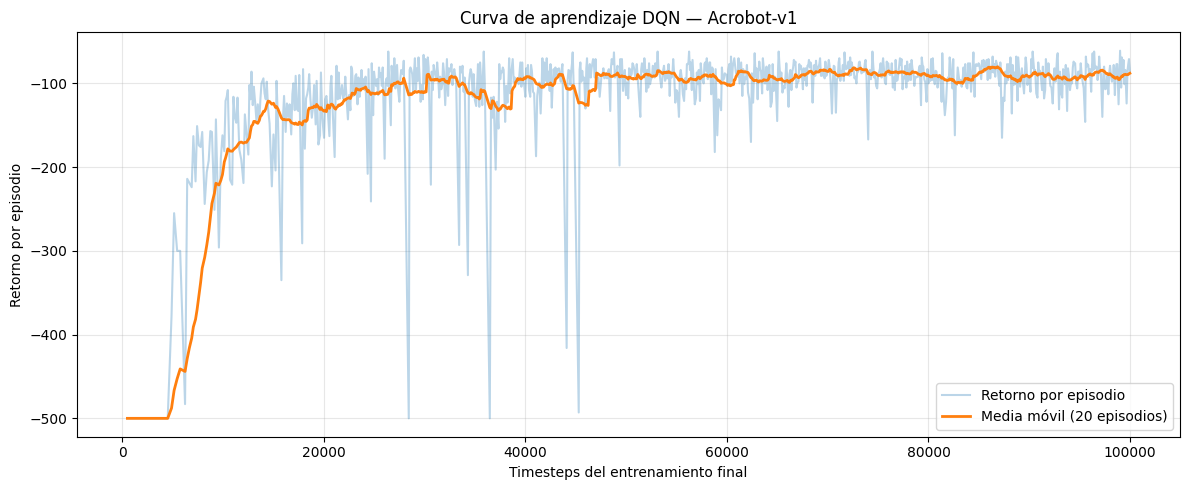

Timesteps considerados: 500 a 99990


,timesteps,episode_return,media_movil_20
929,99666,-124.0,-89.70
930,99752,-85.0,-89.55
931,99830,-77.0,-89.45
932,99902,-71.0,-88.50
933,99990,-87.0,-87.95


In [20]:
# 8. Curva de aprendizaje corregida
# Conserva únicamente el entrenamiento final de 100.000 timesteps

from stable_baselines3.common.results_plotter import load_results, ts2xy
import pandas as pd
import matplotlib.pyplot as plt

monitor_df = load_results(str(LOG_DIR))
timesteps, episode_returns = ts2xy(monitor_df, "timesteps")

learning_df = pd.DataFrame({
    "timesteps": timesteps,
    "episode_return": episode_returns
})

# Tomar únicamente el entrenamiento final
TOTAL_TIMESTEPS = HYPERPARAMS["total_timesteps"]

ultimo_timestep = learning_df["timesteps"].max()

inicio_entrenamiento_final = max(
    0,
    ultimo_timestep - TOTAL_TIMESTEPS
)

learning_df = learning_df[
    learning_df["timesteps"] > inicio_entrenamiento_final
].copy()

# Reiniciar el eje temporal del entrenamiento final
learning_df["timesteps"] = (
    learning_df["timesteps"] - inicio_entrenamiento_final
)

# Media móvil de 20 episodios
learning_df["media_movil_20"] = (
    learning_df["episode_return"]
    .rolling(window=20, min_periods=1)
    .mean()
)

# Guardar CSV
learning_df.to_csv(
    RESULTS_DIR / "dqn_learning_curve.csv",
    index=False
)

# Generar gráfica
plt.figure(figsize=(12, 5))

plt.plot(
    learning_df["timesteps"],
    learning_df["episode_return"],
    alpha=0.30,
    label="Retorno por episodio"
)

plt.plot(
    learning_df["timesteps"],
    learning_df["media_movil_20"],
    linewidth=2,
    label="Media móvil (20 episodios)"
)

plt.title("Curva de aprendizaje DQN — Acrobot-v1")
plt.xlabel("Timesteps del entrenamiento final")
plt.ylabel("Retorno por episodio")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "dqn_learning_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"Timesteps considerados: "
    f"{learning_df['timesteps'].min():.0f} "
    f"a {learning_df['timesteps'].max():.0f}"
)

display(learning_df.tail())

**Observaciones.** Con los datos de `results/dqn_learning_curve.csv` (934 episodios) se distinguen cuatro fases:

| Fase | Timesteps | Episodios | Retorno promedio | Episodios resueltos |
|---|---|---:|---:|---:|
| Inicial | 0 a 4.900 | 10 | -487.8 | 10 % |
| Despegue | 4.900 a 12.000 | 35 | -196.7 | 100 % |
| Mejora progresiva | 12.000 a 50.000 | 343 | -110.3 | 99.4 % |
| Meseta | 50.000 a 100.000 | 546 | -90.6 | 100 % |

- Al principio epsilon está cerca de 1 y el agente se queda en -500. El primer episodio resuelto aparece en el timestep 4.879.
- Cuando el buffer ya tiene algunos episodios exitosos, la media móvil sube rápido. Epsilon llega a 0.1 en el timestep 12.000.
- La media móvil cruza -100 por primera vez en el timestep 26.991, después de 167 episodios. En esta fase hubo todavía dos episodios truncados (timesteps 28.424 y 36.467).
- Desde unos 50.000 timesteps ya no hay episodios truncados y la media móvil se mueve entre -103 y -80. Termina en -87.95.

Hay más episodios en la meseta porque cada uno dura menos. La segunda mitad del entrenamiento aportó más estabilidad que mejora en el retorno.

## 9. Evaluación final del agente

In [21]:
# ============================================================
# 9. Evaluación final del agente DQN
# ============================================================

import gymnasium as gym
import numpy as np
import pandas as pd
from pathlib import Path

ENV_ID = "Acrobot-v1"
SEED = 42
N_EVAL_EPISODES = 30

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

returns = []
episode_lengths = []
successes = []

for episode in range(N_EVAL_EPISODES):
    env = gym.make(ENV_ID)
    obs, info = env.reset(seed=SEED + episode)
    terminated = False
    truncated = False
    episode_return = 0.0
    episode_length = 0

    while not (terminated or truncated):
        action, _ = model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = env.step(action)
        episode_return += float(reward)
        episode_length += 1

    returns.append(episode_return)
    episode_lengths.append(episode_length)
    successes.append(bool(terminated))  # En Acrobot, terminated=True implica alcanzar la meta
    env.close()

returns = np.asarray(returns, dtype=float)
episode_lengths = np.asarray(episode_lengths, dtype=int)
successes = np.asarray(successes, dtype=bool)

evaluation_df = pd.DataFrame({
    "episodio": np.arange(1, N_EVAL_EPISODES + 1),
    "retorno": returns,
    "longitud": episode_lengths,
    "exito": successes.astype(int),
})
evaluation_df.to_csv(RESULTS_DIR / "dqn_evaluation.csv", index=False)

dqn_returns = returns.copy()
dqn_summary = {
    "retorno_promedio": float(returns.mean()),
    "desviacion_estandar": float(returns.std(ddof=1)),
    "retorno_minimo": float(returns.min()),
    "retorno_maximo": float(returns.max()),
    "longitud_promedio": float(episode_lengths.mean()),
    "tasa_exito": float(successes.mean()),
}

evaluation_summary = pd.DataFrame({
    "Métrica": [
        "Episodios evaluados", "Retorno promedio", "Desviación estándar",
        "Retorno mínimo", "Retorno máximo", "Longitud promedio", "Tasa de éxito"
    ],
    "Valor": [
        N_EVAL_EPISODES,
        dqn_summary["retorno_promedio"],
        dqn_summary["desviacion_estandar"],
        dqn_summary["retorno_minimo"],
        dqn_summary["retorno_maximo"],
        dqn_summary["longitud_promedio"],
        dqn_summary["tasa_exito"],
    ]
})
display(evaluation_summary)

print("\nRESULTADO FINAL DQN")
print("=" * 50)
print(f"Episodios evaluados : {N_EVAL_EPISODES}")
print(f"Retorno promedio     : {dqn_summary['retorno_promedio']:.2f}")
print(f"Desviación estándar  : {dqn_summary['desviacion_estandar']:.2f}")
print(f"Retorno mínimo       : {dqn_summary['retorno_minimo']:.2f}")
print(f"Retorno máximo       : {dqn_summary['retorno_maximo']:.2f}")
print(f"Longitud promedio    : {dqn_summary['longitud_promedio']:.2f}")
print(f"Tasa de éxito        : {100*dqn_summary['tasa_exito']:.1f}%")


,Métrica,Valor
0,Episodios evaluados,30.000000
1,Retorno promedio,-83.300000
2,Desviación estándar,14.027436
3,Retorno mínimo,-120.000000
4,Retorno máximo,-63.000000
5,Longitud promedio,84.300000
6,Tasa de éxito,1.000000



RESULTADO FINAL DQN
Episodios evaluados : 30
Retorno promedio     : -83.30
Desviación estándar  : 14.03
Retorno mínimo       : -120.00
Retorno máximo       : -63.00
Longitud promedio    : 84.30
Tasa de éxito        : 100.0%


,Agente,Retorno promedio,Desv. estándar,Longitud promedio,Tasa de éxito
0,Baseline aleatorio,-500.0,0.000000,500.0,0.0
1,DQN,-83.3,14.027436,84.3,1.0


Mejora absoluta del retorno promedio: 416.70
Reducción promedio de pasos: 415.70 (83.14%)


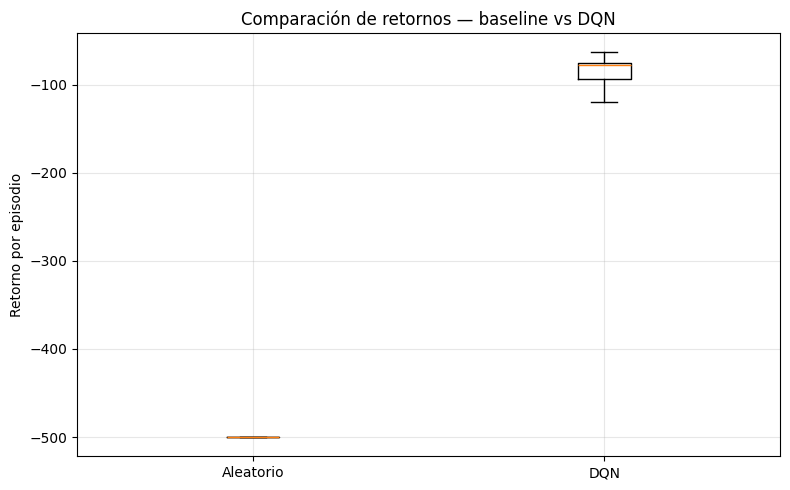

In [22]:
# ============================================================
# 9.1 Comparación cuantitativa: baseline vs DQN
# ============================================================

improvement = dqn_summary["retorno_promedio"] - baseline_summary["retorno_promedio"]
step_reduction = baseline_summary["longitud_promedio"] - dqn_summary["longitud_promedio"]
step_reduction_pct = 100 * step_reduction / baseline_summary["longitud_promedio"]

comparison_df = pd.DataFrame([
    {
        "Agente": "Baseline aleatorio",
        "Retorno promedio": baseline_summary["retorno_promedio"],
        "Desv. estándar": baseline_summary["desviacion_estandar"],
        "Longitud promedio": baseline_summary["longitud_promedio"],
        "Tasa de éxito": baseline_summary["tasa_exito"],
    },
    {
        "Agente": "DQN",
        "Retorno promedio": dqn_summary["retorno_promedio"],
        "Desv. estándar": dqn_summary["desviacion_estandar"],
        "Longitud promedio": dqn_summary["longitud_promedio"],
        "Tasa de éxito": dqn_summary["tasa_exito"],
    },
])
display(comparison_df)

print(f"Mejora absoluta del retorno promedio: {improvement:.2f}")
print(f"Reducción promedio de pasos: {step_reduction:.2f} ({step_reduction_pct:.2f}%)")

plt.figure(figsize=(8, 5))
plt.boxplot([baseline_returns, dqn_returns], tick_labels=["Aleatorio", "DQN"])
plt.title("Comparación de retornos — baseline vs DQN")
plt.ylabel("Retorno por episodio")
plt.grid(alpha=.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "comparacion_retornos.png", dpi=300, bbox_inches="tight")
plt.show()


**Observaciones.** La mejora es de 416.7 puntos: el agente resuelve en 84 pasos lo que la política aleatoria no logra en 500. La desviación del DQN (14.03) es muy pequeña frente a esa diferencia.

La mediana de la evaluación es -77.5, mejor que el promedio. La mayoría de episodios está entre -94 y -75, y solo 4 de 30 pasan de 100 pasos. El promedio baja por unos pocos estados iniciales que le cuestan más al agente.

También nos llamó la atención que el mejor episodio de cada semilla queda entre -62 y -68 (sección 11). Creemos que eso está cerca del mínimo que permite la física del problema: con un torque de ±1, el sistema necesita alrededor de 60 pasos para acumular la energía suficiente.

## 10. Resumen cuantitativo y evidencia final

La comparación utiliza el mismo ambiente y separa el entrenamiento de la evaluación determinista. Además de la curva de aprendizaje, se reportan métricas finales sobre 30 episodios y se contrasta el DQN con una política aleatoria.


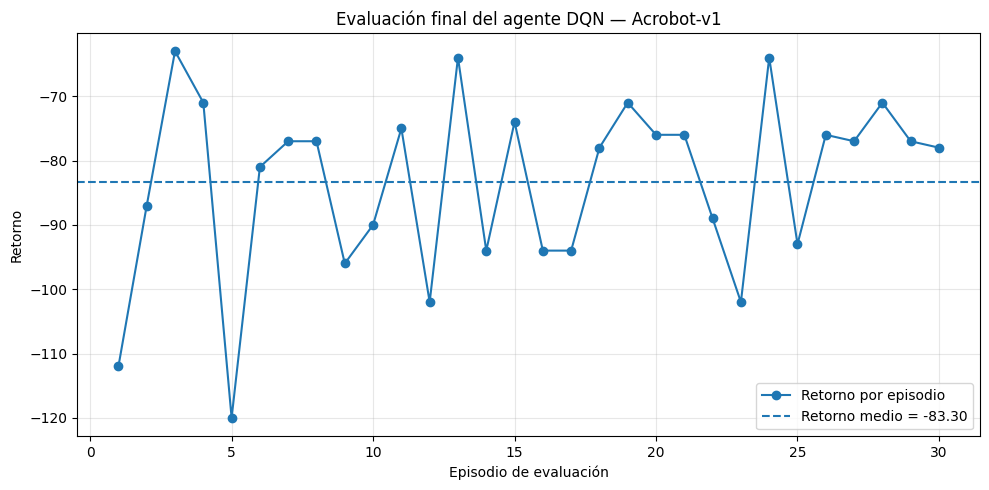

In [23]:
# ============================================================
# 10. Gráfica de evaluación final
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    evaluation_df["episodio"],
    evaluation_df["retorno"],
    marker="o",
    label="Retorno por episodio"
)

plt.axhline(
    returns.mean(),
    linestyle="--",
    label=f"Retorno medio = {returns.mean():.2f}"
)

plt.title("Evaluación final del agente DQN — Acrobot-v1")
plt.xlabel("Episodio de evaluación")
plt.ylabel("Retorno")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "dqn_evaluation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 11. Comparación entre semillas

Para revisar si el resultado depende de una sola inicialización, se compara el desempeño de DQN con tres semillas: `42`, `25` y `123`. Cada modelo se evaluó durante 30 episodios deterministas. Esta sección usa los archivos generados en `results/seed_comparison/` y no vuelve a entrenar los modelos.


,seed,retorno_promedio,desviacion_estandar,retorno_minimo,retorno_maximo,longitud_promedio,tasa_exito
0,25,-80.333333,17.784793,-147.0,-68.0,81.333333,1.0
1,42,-83.300000,14.027436,-120.0,-63.0,84.300000,1.0
2,123,-76.133333,12.447776,-104.0,-62.0,77.133333,1.0


,semillas,retorno_promedio_entre_semillas,retorno_std_entre_semillas,longitud_promedio_entre_semillas,tasa_exito_promedio
0,"42,25,123",-79.922222,3.600977,80.922222,1.0


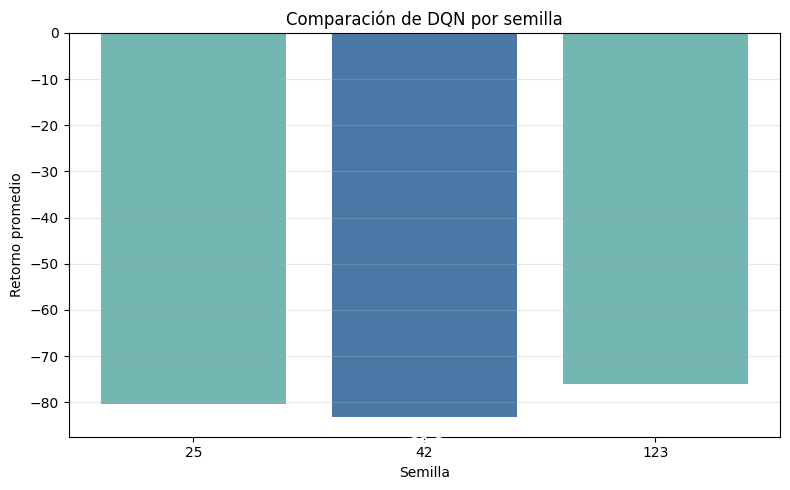

Lectura del comparativo:
Las tres semillas alcanzan 100% de éxito. Los retornos promedio son cercanos, por lo que el resultado no depende únicamente de la semilla 42.


In [24]:
# 11. Comparación entre semillas

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

SEED_RESULTS_DIR = Path("results/seed_comparison")
summary_path = SEED_RESULTS_DIR / "seed_summary.csv"
aggregate_path = SEED_RESULTS_DIR / "seed_aggregate.csv"
figure_path = SEED_RESULTS_DIR / "seed_return_comparison.png"

if not summary_path.exists():
    raise FileNotFoundError(
        "No se encontró results/seed_comparison/seed_summary.csv. "
        "Ejecute primero seed_comparison.py para generar el comparativo."
    )

seed_summary_df = pd.read_csv(summary_path).sort_values("seed")
display(seed_summary_df)

if aggregate_path.exists():
    seed_aggregate_df = pd.read_csv(aggregate_path)
    display(seed_aggregate_df)

plt.figure(figsize=(8, 5))
colors = ["#4C78A8" if seed == 42 else "#72B7B2" for seed in seed_summary_df["seed"]]
plt.bar(seed_summary_df["seed"].astype(str), seed_summary_df["retorno_promedio"], color=colors)
plt.title("Comparación de DQN por semilla")
plt.xlabel("Semilla")
plt.ylabel("Retorno promedio")
plt.grid(axis="y", alpha=0.3)

for idx, row in seed_summary_df.reset_index(drop=True).iterrows():
    plt.text(idx, row["retorno_promedio"] - 4, f"{row['retorno_promedio']:.1f}", ha="center", va="top", color="white", fontweight="bold")

plt.tight_layout()
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Lectura del comparativo:")
print("Las tres semillas alcanzan 100% de éxito. Los retornos promedio son cercanos, por lo que el resultado no depende únicamente de la semilla 42.")



**Observaciones.** Con tres semillas, el intervalo de confianza del 95 % para el retorno promedio va de -88.9 a -71.0 (t de Student con 2 grados de libertad). Todo el intervalo está por encima de -100. Si se juntan los 90 episodios evaluados, la mediana es -76.5 y 82 de los 90 se resolvieron en menos de 100 pasos.

La semilla 42, que usamos en el análisis principal, es la de peor promedio de las tres, así que los resultados de las secciones 9 y 10 son más bien conservadores. La semilla 25 tiene el peor episodio individual (-147), aunque su promedio es bueno.

## 12. Reflexión de resultados

El agente DQN presenta una mejora sustancial frente al baseline aleatorio. La política aleatoria obtuvo un retorno promedio de **-500.00**, una longitud promedio de **500 pasos** y una tasa de éxito de **0 %**, lo que indica que no alcanzó la meta dentro del límite del episodio. En contraste, la evaluación final del DQN sobre 30 episodios produjo un retorno promedio de **-83.30 ± 14.03**, con valores entre **-120** y **-63**, y una longitud promedio de **84.30 pasos**. La tasa de éxito observada fue **100 %**.

La mejora del retorno promedio es de **416.70 puntos** respecto al baseline y la longitud media del episodio se reduce en **83.14 %**. Esto es coherente con la función de recompensa de Acrobot: cada paso no terminal penaliza con -1 y alcanzar la meta termina el episodio, por lo que un retorno menos negativo representa una solución más rápida.

La curva de aprendizaje muestra una fase inicial de desempeño pobre y alta variabilidad, seguida por una mejora rápida hasta una región estable de retornos mucho menos negativos. Las fluctuaciones que permanecen son razonables porque el estado inicial es estocástico y algunas configuraciones requieren secuencias distintas de torque para acumular energía. La evaluación final, realizada de manera determinista y separada del entrenamiento, confirma que el comportamiento aprendido generaliza a múltiples reinicios del ambiente.

Como limitaciones, el presupuesto fue de 100.000 timesteps y se usó una configuración de hiperparámetros tomada de RL Baselines3 Zoo, sin búsqueda propia. Para revisar la dependencia de la semilla repetimos el entrenamiento con las semillas 25 y 123 (sección 11): las tres resolvieron todos los episodios, con un promedio conjunto de -79.92. Aun así, tres semillas siguen siendo pocas para comparar configuraciones que den resultados parecidos.


## 13. Reflexión sobre lo que más costó

Las dificultades principales fueron tanto conceptuales como técnicas. Primero, fue necesario interpretar correctamente la observación de Acrobot: los ángulos no aparecen directamente, sino mediante seno y coseno, junto con las velocidades angulares. Esto obliga a comprender que la red recibe una representación continua de seis dimensiones y no imágenes.

Segundo, al inicio resulta contraintuitivo que el aprendizaje mejore aunque las recompensas sigan siendo negativas. En este ambiente el objetivo no es obtener una gran recompensa positiva, sino reducir el número de pasos necesarios para alcanzar la meta; por eso pasar de **-500** a un retorno promedio cercano a **-83.30** representa una mejora muy grande.

Tercero, fue necesario diferenciar con claridad el papel de cada componente de DQN: la política ε-greedy controla exploración/explotación, el replay buffer desacopla temporalmente las muestras, la red target estabiliza el objetivo de Bellman y la red online es la que se actualiza mediante descenso de gradiente. Confundir cualquiera de estos elementos altera la interpretación del flujo de entrenamiento.

Finalmente, el reto técnico más importante fue mantener un pipeline reproducible: fijar semillas, registrar episodios con `Monitor`, separar entrenamiento y evaluación, evitar mezclar logs de ejecuciones anteriores y conservar únicamente el tramo correspondiente al entrenamiento final de 100.000 timesteps. Esta parte fue necesaria para que la curva presentada realmente representara el experimento final y no una combinación de pruebas previas.

Otra cosa que aprendimos es cuánto puede variar una corrida a otra. Con la misma configuración, el promedio fue -83.30 con la semilla 42 y -76.13 con la 123, y la semilla 25 tuvo un episodio de -147 aunque su promedio fue bueno. Por eso preferimos reportar las tres semillas. También tuvimos que revisar las cifras del texto contra los CSV, porque después de repetir ejecuciones algunos valores habían quedado de corridas anteriores.


## 14. Conclusiones

Con la semilla principal, el agente pasó de no resolver nunca el ambiente con la política aleatoria a resolver los 30 episodios de evaluación, con un promedio de 84.30 pasos frente a los 500 del baseline. La media móvil del entrenamiento cruzó -100 cerca del timestep 27.000 y el entrenamiento completo tomó menos de tres minutos en CPU.

Al repetir el entrenamiento con las semillas 25 y 123 obtuvimos resultados muy parecidos: las tres resolvieron todos los episodios, con promedios entre -76 y -83. Por eso consideramos que el aprendizaje no depende de una inicialización favorable, aunque con tres semillas el intervalo de confianza todavía es amplio (de -88.9 a -71.0) y valdría la pena repetirlo con más.

En el comportamiento del agente se reconoce el papel de cada componente de DQN. Mientras epsilon estuvo alto el agente se quedó en -500, y en cuanto el replay buffer tuvo los primeros episodios exitosos el retorno mejoró rápido. La red target y el buffer permitieron que esa mejora fuera estable: después de los 50.000 timesteps no hubo más episodios truncados. Al final, la exploración residual de 0.1 explica que la evaluación determinista sea unos 7 pasos mejor que el entrenamiento. También ayudó que el ambiente se preste para DQN: el estado es un vector de seis variables, suficiente para una MLP, y solo hay tres acciones discretas.

### Referencias

- Mnih, V., et al. (2013). *Playing Atari with Deep Reinforcement Learning*. arXiv:1312.5602.
- Mnih, V., et al. (2015). *Human-level control through deep reinforcement learning*. Nature, 518.
- Sutton, R. y Barto, A. (2018). *Reinforcement Learning: An Introduction* (2.ª ed.). MIT Press.
- Lapan, M. (2024). *Deep Reinforcement Learning Hands-On* (3.ª ed.). Packt.
- Documentación de Stable-Baselines3 (DQN), RL Baselines3 Zoo y Gymnasium (`Acrobot-v1`).